# Extracción de caracteristicas y generación del vector de caracteristicas

-----
Carlos Francisco Montoya Urzúa

21 de mayo de 2025

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
import cv2
import numpy as np
from skimage.feature import local_binary_pattern

def extraer_caracteristicas(ruta_imagen):
    # 1. Cargar imagen y convertir a HSV y escala de grises
    imagen_bgr = cv2.imread(ruta_imagen)
    imagen_hsv = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2HSV)
    imagen_gray = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)

    # 2. Histograma de color (HSV)
    hist_h = cv2.calcHist([imagen_hsv], [0], None, [8], [0, 180]).flatten()
    hist_s = cv2.calcHist([imagen_hsv], [1], None, [8], [0, 256]).flatten()
    hist_v = cv2.calcHist([imagen_hsv], [2], None, [8], [0, 256]).flatten()
    hist_color = np.concatenate((hist_h, hist_s, hist_v))
    hist_color = hist_color / np.sum(hist_color)  # normalización

    # 3. Características de forma: contornos
    _, binaria = cv2.threshold(imagen_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contornos:
        mayor_contorno = max(contornos, key=cv2.contourArea)
        area = cv2.contourArea(mayor_contorno)
        perimetro = cv2.arcLength(mayor_contorno, True)
        momentos = cv2.moments(mayor_contorno)
        if momentos['m00']==0: momentos['m00']=1
        cx = int(momentos['m10']/momentos['m00']) if momentos['m00'] != 0 else 0
        cy = int(momentos['m01']/momentos['m00']) if momentos['m00'] != 0 else 0
    else:
        area = perimetro = cx = cy = 0

    forma = np.array([area, perimetro, cx, cy], dtype=np.float32)

    # 4. Características de textura: LBP
    lbp = local_binary_pattern(imagen_gray, P=8, R=1, method='uniform')
    (hist_lbp, _) = np.histogram(lbp.ravel(), bins=np.arange(0, 10), range=(0, 9))
    hist_lbp = hist_lbp.astype("float")
    hist_lbp /= (hist_lbp.sum() + 1e-7)

    # 5. Características de puntos clave: ORB
    orb = cv2.ORB_create()
    keypoints, descriptores = orb.detectAndCompute(imagen_gray, None)
    num_keypoints = len(keypoints)
    orb_feature = np.array([num_keypoints], dtype=np.float32)

    # 6. Concatenar todas las características
    vector_final = np.concatenate([hist_color, forma, hist_lbp, orb_feature])

    return vector_final
### **Ejemplo de uso:**

vector = extraer_caracteristicas('/content/drive/MyDrive/Colab Notebooks/manzana.jpg')
print("Vector de características:", vector.shape)
print(vector)

Vector de características: (38,)
[1.62841961e-01 3.88740376e-02 3.75540368e-03 5.12820529e-03
 3.39900330e-03 3.02280299e-03 4.65300446e-03 1.11658908e-01
 1.57383755e-01 2.27964222e-02 1.24872122e-02 1.03950100e-02
 1.33056138e-02 2.58786250e-02 4.41012457e-02 4.69854474e-02
 1.32000132e-05 2.07240204e-03 1.72722172e-02 3.38448323e-02
 4.67016473e-02 3.71580385e-02 2.15886217e-02 1.74682379e-01
 5.00520000e+04 9.04000000e+02 1.29000000e+02 9.70000000e+01
 2.68488268e-02 4.76784477e-02 2.94030294e-02 7.54776755e-02
 1.54836155e-01 1.50618751e-01 5.22126522e-02 6.39540640e-02
 3.98970399e-01 3.43000000e+02]


array([[[252, 252, 252],
        [252, 252, 252],
        [252, 252, 252],
        ...,
        [252, 252, 252],
        [252, 252, 252],
        [252, 252, 252]],

       [[252, 252, 252],
        [252, 252, 252],
        [252, 252, 252],
        ...,
        [252, 252, 252],
        [252, 252, 252],
        [252, 252, 252]],

       [[252, 252, 252],
        [252, 252, 252],
        [252, 252, 252],
        ...,
        [252, 252, 252],
        [252, 252, 252],
        [252, 252, 252]],

       ...,

       [[252, 252, 252],
        [252, 252, 252],
        [252, 252, 252],
        ...,
        [252, 252, 252],
        [252, 252, 252],
        [252, 252, 252]],

       [[252, 252, 252],
        [252, 252, 252],
        [252, 252, 252],
        ...,
        [252, 252, 252],
        [252, 252, 252],
        [252, 252, 252]],

       [[252, 252, 252],
        [252, 252, 252],
        [252, 252, 252],
        ...,
        [252, 252, 252],
        [252, 252, 252],
        [252, 252, 252]]], dtype=uint8)
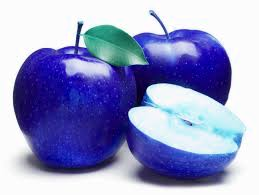

In [6]:
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/manzana.jpg')
img